# 11 · Model: which problems should a renter expect?
**Know Before You Rent · Team BUTA**

**Q5:** for a given building, how likely is each problem type next four months, and why?

- **One classifier per problem type:** heat/hot water, pests, leaks/mold, plumbing, paint/plaster, doors/windows, safety.
- **Train** on the 2025 training table (history January–June 2025). **Test** on the matching 2026 windows (history January–June 2026), a year the model never saw.
- **Models compared:**
  1. **Baseline:** "it will happen again if it happened before".
  2. **Logistic regression:** simple, and explainable.
  3. **Gradient-boosted trees:** flexible, and handles missing values.
- **Metrics:**
  - **AUC:** how well the model ranks risky buildings above safe ones. 0.5 is random, 1 is perfect.
  - **Average precision:** how well it finds the buildings that actually get the problem. Compare it to the base rate.
  - **Brier score:** how accurate the probabilities themselves are. Lower is better.

Code: `src/model_housing.py`.

**Study window: January 1, 2025–October 31, 2026.** Annual comparisons should use January–October in both years. Housing prediction uses six-month histories and four-month outcomes; older figures and reports describe the previous study.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))

import joblib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src import features_housing as F, model_housing as M
from src.plots import save, ACCENT, MUTED

pd.set_option("display.float_format", "{:,.3f}".format)
train = pd.read_parquet(str(F.FEATURES_FILE).format(window="train"))
test = pd.read_parquet(str(F.FEATURES_FILE).format(window="test"))
cols = F.feature_columns(train)
print(f"train {len(train):,} buildings | test {len(test):,} | {len(cols)} features")
{k: len(v) for k, v in M.feature_groups(cols).items()}

train 172,468 buildings | test 172,468 | 56 features


{'building': 6, 'history': 25, 'landlord': 9, 'neighborhood': 8, 'crime': 8}

## 1. Baseline vs logistic regression vs gradient boosting

In [2]:
RETRAIN = False
artifact_path = M.MODELS_DIR / "kbyr_models.joblib"
artifact = joblib.load(artifact_path) if artifact_path.exists() else None
reuse = not RETRAIN and artifact is not None and artifact.get("study", {}).get("study_id") == F.config.STUDY_ID
if reuse:
    assert artifact["features"] == cols
    results = pd.read_csv(F.config.REPORTS_DIR / "model_results.csv")
    fitted = artifact["models"]
else:
    results, fitted = M.evaluate(train, test)
pivot = results.pivot(index="problem", columns="model", values="auc")[["baseline: had it before", "logit", "gbm"]]
display(pivot.style.format("{:.3f}").background_gradient(cmap="Purples", axis=1).set_caption("Test AUC (Jul–Oct 2026)"))
results.pivot(index="problem", columns="model", values="avg_precision").join(
    results.drop_duplicates("problem").set_index("problem")["base_rate"])

model,baseline: had it before,logit,gbm
problem,,,
doors/windows,0.735,0.901,0.927
heat/hot water,0.825,0.888,0.916
leaks/mold,0.740,0.884,0.913
paint/plaster,0.748,0.901,0.927
pests,0.721,0.885,0.914
plumbing,0.748,0.894,0.919
safety,0.624,0.866,0.901


,baseline: had it before,gbm,logit,base_rate
problem,,,,
doors/windows,0.301,0.485,0.441,0.044
heat/hot water,0.413,0.498,0.451,0.057
leaks/mold,0.362,0.546,0.499,0.068
paint/plaster,0.346,0.537,0.494,0.052
pests,0.322,0.520,0.476,0.058
plumbing,0.338,0.528,0.483,0.055
safety,0.091,0.216,0.190,0.018


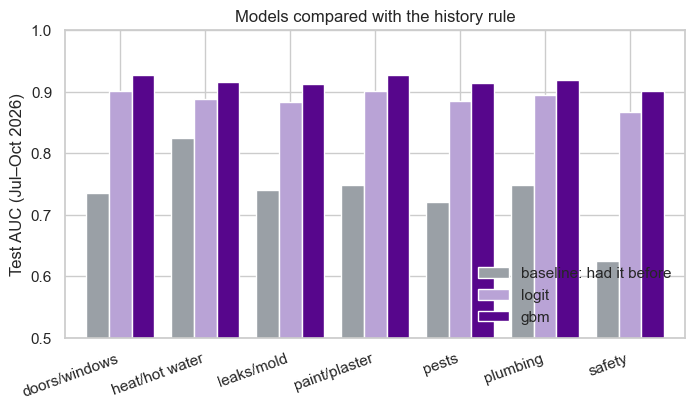

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
pivot.plot(kind="bar", ax=ax, color=[MUTED, "#b9a3d6", ACCENT], width=0.8)
ax.set(ylim=(0.5, 1), ylabel="Test AUC (Jul–Oct 2026)", xlabel="", title="Models compared with the history rule")
ax.legend(frameon=False, loc="lower right"); plt.xticks(rotation=20, ha="right")
save(fig, "rent10a_model_comparison")

## 2. Which information matters? Feature-group ablation
Start with building traits only, then add own history, then the landlord, then the 100 m neighborhood, then reported crime within 200 m. Each step is retrained and scored on 2025.

In [4]:
# Reuse the same-window app evaluation (AUC stored to four decimals).
import json
insight_path = F.config.PROCESSED_DIR / "app_insights.json"
cached = json.loads(insight_path.read_text()) if insight_path.exists() else {}
if not RETRAIN and cached.get("study", {}).get("study_id") == F.config.STUDY_ID:
    a = cached["model"]["ablation"]
    step_names = [" + ".join(a["steps"][:i + 1]) for i in range(len(a["steps"]))]
    abl_auc = pd.DataFrame.from_dict(a["series"], orient="index", columns=step_names)
else:
    abl = M.ablation(train, test)
    abl_auc = abl.pivot(index="problem", columns="features", values="auc")
abl_auc = abl_auc[sorted(abl_auc.columns, key=len)]
display(abl_auc.style.format("{:.3f}").background_gradient(cmap="Purples", axis=1))
gain = abl_auc.diff(axis=1).iloc[:, 1:]
gain.columns = ["+ " + c.split(" + ")[-1] for c in gain.columns]
gain.style.format("{:+.3f}").set_caption("AUC gained by each added group")

,building,building + history,building + history + landlord,building + history + landlord + neighborhood,building + history + landlord + neighborhood + crime
heat/hot water,0.868,0.913,0.915,0.916,0.916
pests,0.859,0.909,0.911,0.913,0.914
leaks/mold,0.858,0.907,0.911,0.912,0.913
plumbing,0.863,0.915,0.917,0.918,0.919
paint/plaster,0.875,0.923,0.926,0.927,0.927
doors/windows,0.865,0.922,0.925,0.926,0.927
safety,0.840,0.899,0.900,0.899,0.901


,+ history,+ landlord,+ neighborhood,+ crime
heat/hot water,+0.045,+0.002,+0.001,+0.000
pests,+0.050,+0.002,+0.002,+0.001
leaks/mold,+0.049,+0.005,+0.001,+0.001
plumbing,+0.052,+0.002,+0.001,+0.001
paint/plaster,+0.048,+0.003,+0.001,+0.001
doors/windows,+0.057,+0.003,+0.001,+0.000
safety,+0.059,+0.001,-0.000,+0.001


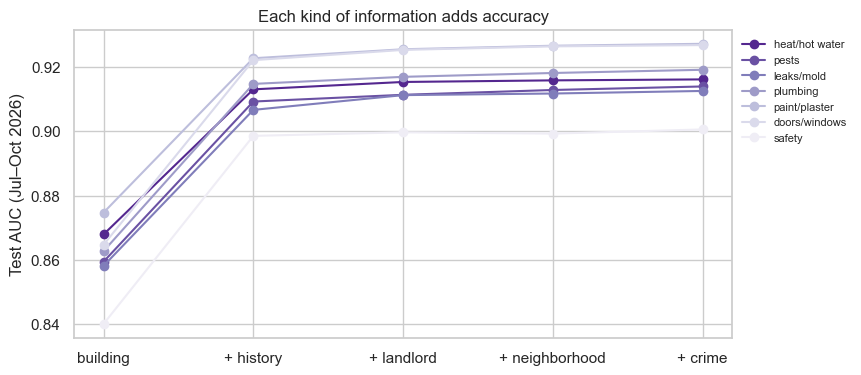

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 4))
for (problem, row), color in zip(abl_auc.iterrows(), sns.color_palette("Purples_r", len(abl_auc))):
    ax.plot(range(len(row)), row.values, "-o", color=color, label=problem)
ax.set_xticks(range(abl_auc.shape[1]), [c.split(" + ")[-1] if i == 0 else "+ " + c.split(" + ")[-1] for i, c in enumerate(abl_auc.columns)])
ax.set(ylabel="Test AUC (Jul–Oct 2026)", title="Each kind of information adds accuracy")
ax.legend(frameon=False, fontsize=8, bbox_to_anchor=(1, 1))
save(fig, "rent10b_ablation")

## 3. Permutation importance by group (gradient boosting, all features)
How much test AUC drops when one group's columns are shuffled.

In [6]:
imp_rows, per_feature = [], {}
for problem in F.TARGET_TYPES:
    g, pf = M.group_importance(fitted[(problem, "gbm")], test, problem)
    imp_rows.append(g); per_feature[problem] = pf
imp = pd.DataFrame(imp_rows)
display(imp.style.format("{:.3f}").background_gradient(cmap="Purples", axis=1))
pd.DataFrame(per_feature).mean(axis=1).sort_values(ascending=False).head(15).rename("mean AUC drop").to_frame()

,building,history,landlord,neighborhood,crime
heat/hot water,0.029,0.046,0.003,0.001,0.003
pests,0.024,0.042,0.003,0.002,0.004
leaks/mold,0.030,0.041,0.004,0.002,0.002
plumbing,0.020,0.039,0.002,0.001,0.003
paint/plaster,0.024,0.038,0.004,0.002,0.006
doors/windows,0.019,0.040,0.002,0.001,0.003
safety,0.019,0.060,-0.001,-0.000,0.002


,mean AUC drop
c_total,0.039
unitsres,0.019
is_registered,0.004
crime_in_residence,0.002
v_class_B,0.001
nb100_buildings,0.001
ll_rate_heat_hot_water,0.001
building_age,0.001
ll_rate_leaks_mold,0.001
v_class_C,0.001


## 4. Are the probabilities honest? (calibration)

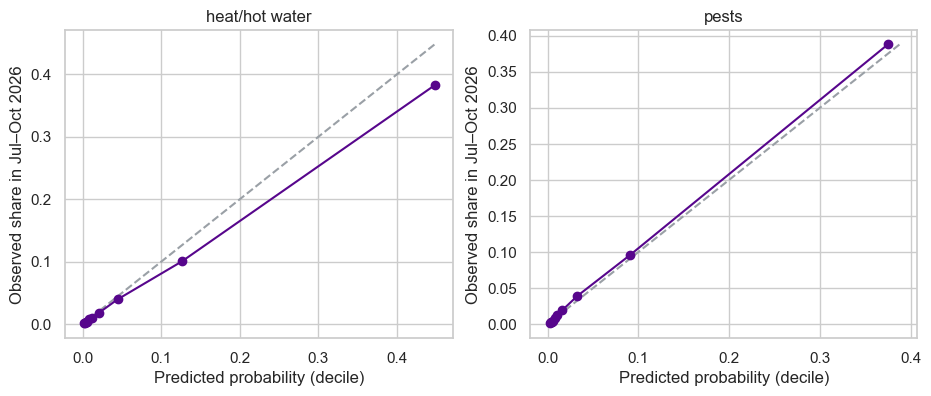

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, problem in zip(axes, ["heat/hot water", "pests"]):
    y = test[f"y_{F.slug(problem)}"]
    p = fitted[(problem, "gbm")].predict_proba(M.to_matrix(test, cols))[:, 1]
    bins = pd.qcut(p, 10, duplicates="drop")
    cal = pd.DataFrame({"pred": p, "obs": y}).groupby(bins, observed=True).mean()
    ax.plot([0, cal.max().max()], [0, cal.max().max()], "--", color=MUTED)
    ax.plot(cal["pred"], cal["obs"], "-o", color=ACCENT)
    ax.set(title=problem, xlabel="Predicted probability (decile)", ylabel="Observed share in Jul–Oct 2026")
save(fig, "rent10c_calibration")

## 5. From probability to a renter report

In [8]:
base = {p: train[f"y_{F.slug(p)}"].mean() for p in F.TARGET_TYPES}
X_te = M.to_matrix(test, cols)
probs = pd.DataFrame({p: fitted[(p, "gbm")].predict_proba(X_te)[:, 1] for p in F.TARGET_TYPES}, index=test.index)
levels = pd.DataFrame({p: M.risk_level(probs[p], base[p]) for p in F.TARGET_TYPES}, index=test.index)

# How well do the levels separate risk? Observed 2025 rate per level
check = {p: test.groupby(levels[p])[f"y_{F.slug(p)}"].mean() for p in F.TARGET_TYPES}
pd.DataFrame(check).T[["Low", "Medium", "High"]].mul(100).round(1).rename_axis("observed % with problem in Jul–Oct 2026")

,Low,Medium,High
observed % with problem in Jul–Oct 2026,,,
heat/hot water,0.900,6.400,29.800
pests,1.000,6.800,32.000
leaks/mold,1.200,8.600,36.100
plumbing,0.900,6.400,32.400
paint/plaster,0.700,6.000,32.100
doors/windows,0.600,5.300,27.200
safety,0.300,2.200,11.000


In [9]:
def renter_report(i):
    row = test.loc[[i]]
    print(f"BBL {row.bbl.iat[0]} · {row.borough.iat[0]} {row.zipcode.iat[0]} · built {row.yearbuilt.iat[0]:.0f} · "
          f"{row.unitsres.iat[0]:.0f} apartments · landlord portfolio: {row.portfolio_buildings.iat[0]:.0f} buildings")
    for p in sorted(F.TARGET_TYPES, key=lambda p: -probs.at[i, p]):
        reasons = M.explain(fitted[(p, "logit")], row, cols, p)
        print(f"  {levels.at[i, p]:6s} {p:15s} {probs.at[i, p]:.0%}   " + ("; ".join(reasons) if levels.at[i, p] != "Low" else ""))

# Three example buildings: high, typical and low overall risk
overall = probs.mean(axis=1)
for i in [overall.idxmax(), overall.sub(overall.median()).abs().idxmin(), overall.idxmin()]:
    renter_report(i); print()

BBL 4159260001 · QUEENS 11692 · built 1974 · 1091 apartments · landlord portfolio: 210 buildings
  High   pests           97%   evictions = 44.0; this building had 33 pests complaint(s) in the last 6 months; this building had 123 total complaint(s) in the last 6 months
  High   leaks/mold      97%   this building had 123 total complaint(s) in the last 6 months; evictions = 44.0; this building had 29 leaks mold complaint(s) in the last 6 months
  High   paint/plaster   97%   evictions = 44.0; this building had 123 total complaint(s) in the last 6 months; inspectors issued 313 class B violation(s) in the last 6 months
  High   plumbing        96%   this building had 123 total complaint(s) in the last 6 months; evictions = 44.0; inspectors issued 313 class B violation(s) in the last 6 months
  High   heat/hot water  96%   this building had 123 total complaint(s) in the last 6 months; evictions = 44.0; inspectors issued 313 class B violation(s) in the last 6 months
  High   doors/windows  

## 6. Save the models

In [10]:
M.MODELS_DIR.mkdir(exist_ok=True)
from src.study import metadata
joblib.dump({"features": cols, "base_rates": base, "models": fitted, "study": metadata()}, M.MODELS_DIR / "kbyr_models.joblib")
results.to_csv(ROOT / "reports" / "model_results.csv", index=False)
print("Saved models →", (M.MODELS_DIR / "kbyr_models.joblib").relative_to(ROOT))

Saved models → models\kbyr_models.joblib


## Findings

Run the cells above to inspect results for the shared January 2025–October 2026 study. Previous-window metrics are not reused.